In [1]:
import sys
print(sys.version)

!nvidia-smi

3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
Fri Oct 23 04:08:26 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   45C    P8             16W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A

In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

In [ ]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))

Voici un jeu de données sur les fréquences cardiaques de 10 adultes mesurées en nombre de battements par minute:
$$90,\; 60,\; 55,\; 60,\; 68,\; 85,\; 70,\; 75,\; 50,\; 76\;\cdot$$
Analysons ces données en utilisant Python.

**Questions**


1.   Déterminez les mesures de tendance centrale (moyenne, médiane), et de dispersion (variance, écart-type, quartiles).
2.   Résumez graphiquement ces données en utilisant des représentations adéquates.
3.   Ces données semblent-elles provenir d'une distribution normale ? Vérifiez cela à l'aide d'un diagramme QQ-plot.



In [5]:
import numpy as np

data = [90, 60, 55, 60, 68, 85, 70, 75, 50, 76]

# Calculate the mean
mean_data = np.mean(data)

# Calculate the variance
variance_data = np.var(data)
standard_deviation = np.std(data)

# Calculate quartiles (25th, 50th/median, 75th percentiles)
Q1 = np.percentile(data, 25)
Q2 = np.percentile(data, 50) # Median
Q3 = np.percentile(data, 75)
Q90 =np.percentile(data, 90)


print(f"Données: {data}")
print(f"Moyenne (Mean): {mean_data:.2f}")
print(f"Variance: {variance_data:.2f}")
print(f"Premier quartile (Q1): {Q1:.2f}")
print(f"Deuxième quartile (Médiane/Q2): {Q2}")
print(f"Troisième quartile (Q3): {Q3:.2f}")
print(f"90e percentile est: {Q90:.2f}")

Données: [90, 60, 55, 60, 68, 85, 70, 75, 50, 76]
Moyenne (Mean): 68.90
Variance: 150.29
Premier quartile (Q1): 60.00
Deuxième quartile (Médiane/Q2): 69.0
Troisième quartile (Q3): 75.75
90e percentile est: 85.50


Diagramme à bâton (moins utile pour des une variable quantitative continue)


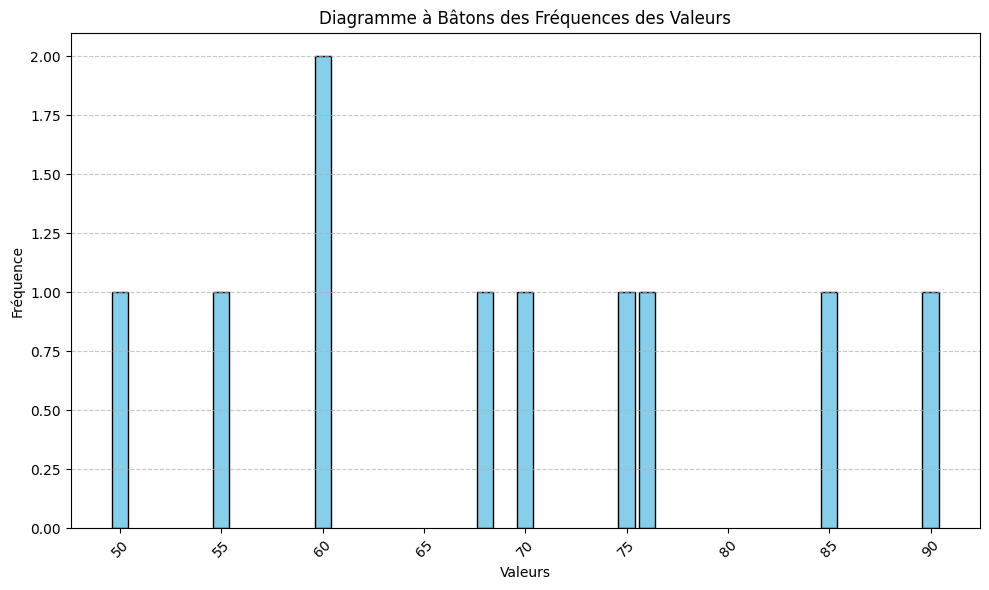

In [6]:
import matplotlib.pyplot as plt
from collections import Counter

# The 'data' variable is available from previous executions
# For reference: data = [90, 60, 55, 60, 68, 85, 70, 75, 50, 76]

# Count the frequency of each unique value
value_counts = Counter(data)

# Prepare data for plotting
labels = list(value_counts.keys())
heights = list(value_counts.values())

# Sort the labels and heights to have a more organized chart
sorted_indices = sorted(range(len(labels)), key=lambda k: labels[k])
sorted_labels = [labels[i] for i in sorted_indices]
sorted_heights = [heights[i] for i in sorted_indices]

plt.figure(figsize=(10, 6))
plt.bar(sorted_labels, sorted_heights, color='skyblue', edgecolor='black')
plt.title('Diagramme à Bâtons des Fréquences des Valeurs')
plt.xlabel('Valeurs')
plt.ylabel('Fréquence')
plt.xticks(rotation=45) # Rotate labels if they overlap
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout() # Adjust layout to prevent labels from being cut off
plt.show()

Histogramme: Regroupement des données par classes de même amplitude (longeurs): plus utile pour un grand nombre de données d'une variable quantitative.

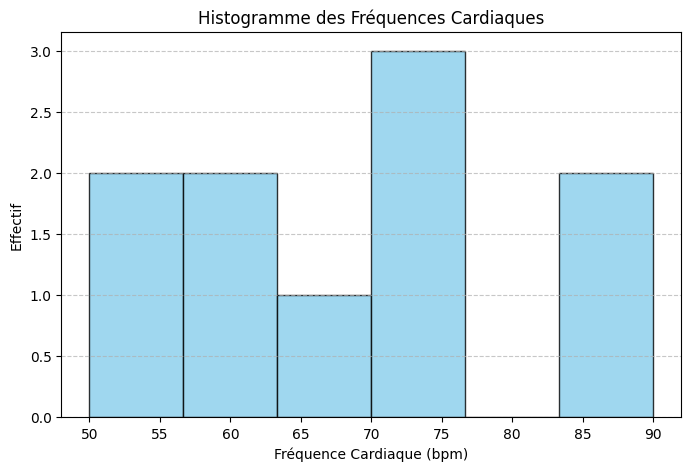

In [7]:
import matplotlib.pyplot as plt

# Données des fréquences cardiaques (FCM)
fcm_data = [90, 60, 55, 60, 68, 85, 70, 75, 50, 76]

plt.figure(figsize=(8, 5))
# Utilisation de bins appropriés pour 10 valeurs
plt.hist(fcm_data, bins=6, color='skyblue', edgecolor='black', alpha=0.8)

plt.title('Histogramme des Fréquences Cardiaques')
plt.xlabel('Fréquence Cardiaque (bpm)')
plt.ylabel('Effectif')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

Diagramme à secteurs:

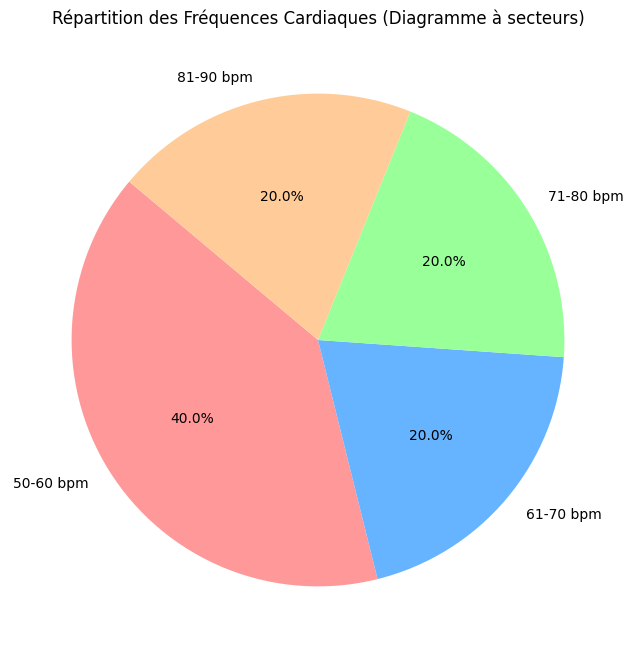

In [8]:
import matplotlib.pyplot as plt
import pandas as pd

# Données des fréquences cardiaques
fcm_data = [90, 60, 55, 60, 68, 85, 70, 75, 50, 76]

# Définir des tranches (classes) pour les fréquences cardiaques
bins = [49, 60, 70, 80, 95]
labels = ['50-60 bpm', '61-70 bpm', '71-80 bpm', '81-90 bpm']

categories = pd.cut(fcm_data, bins=bins, labels=labels)
counts = pd.Series(categories).value_counts()

plt.figure(figsize=(8, 8))
plt.pie(counts, labels=counts.index, autopct='%1.1f%%', startangle=140, colors=['#ff9999','#66b3ff','#99ff99','#ffcc99'])
plt.title('Répartition des Fréquences Cardiaques (Diagramme à secteurs)')
plt.show()

Boxplot (Diagramme à moustache): il résume mieux les données et donne une idée sur l'asymétrie.

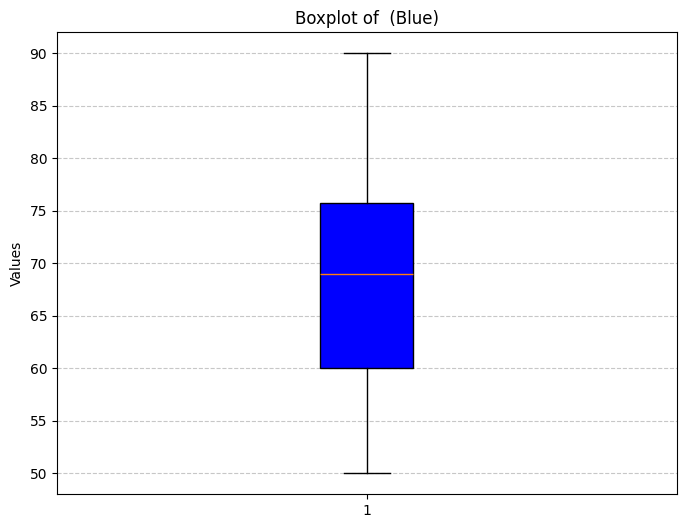

In [11]:
import numpy as np
import matplotlib.pyplot as plt


# The 'data' variable is available from previous executions
data = [90, 60, 55, 60, 68, 85, 70, 75, 50, 76]

plt.figure(figsize=(8, 6)) # Increased width from 8 to 10
bp = plt.boxplot(data, patch_artist=True)

# Set the color of the box to blue
for box in bp['boxes']:
    box.set(facecolor='blue')

plt.title('Boxplot of  (Blue)')
plt.ylabel('Values')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

Vérification de la normalité des données. Ici, c'est difficile de vérifier la nomalité des données avec peu de données.


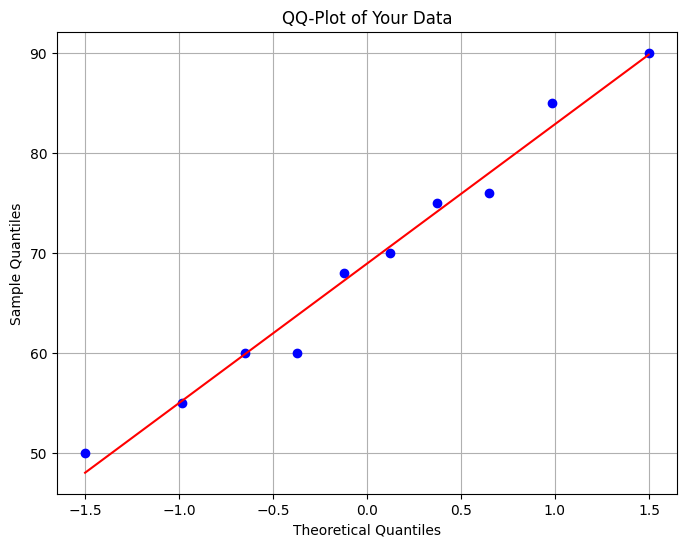

In [12]:
import matplotlib.pyplot as plt
import scipy.stats as stats
import numpy as np

# The 'data' variable is available from the previous execution
# If you wish to use different data, update the 'data' list accordingly.
# For example: data = [90, 60, 55, 60, 68, 85, 70, 75, 50, 76]

fig, ax = plt.subplots(figsize=(8, 6))
stats.probplot(data, dist="norm", plot=ax)
ax.set_title("QQ-Plot of Your Data")
ax.set_xlabel("Theoretical Quantiles")
ax.set_ylabel("Sample Quantiles")
plt.grid(True)
plt.show()

**Nuage de points:** À voir au **Chapitre 6** avec plus de détails. Étude de corrélation entre FC et Âge.

Voici les âges (en année) de 10 adultes associés au jeu de données des fréquences cardiaques de 10 adultes.

**Age** (X: variable explicative): 18,45,57,61,32,21,29,**55**,72,35

**FCM** (Y: variable expliquée): 90,60,55,60,68,85,70,**75**,50,76.


In [14]:
import matplotlib.pyplot as plt
import scipy.stats as stats
import numpy as np
import pandas as pd

# The 'data' variable (heart rates) is available from previous executions
fcm_data = [90, 60, 55, 60, 68, 85, 70, 75, 50, 76] # Explicitly define data

# The provided age data
age_data = [18, 45, 57, 61, 32, 21, 29, 55, 72, 35]

# Create a dictionary for the DataFrame
table_data = {
    'Fréquence Cardiaque (bpm)': age_data,
    'Âge (années)': fcm_data
}

# Create the DataFrame
df_table = pd.DataFrame(table_data)

# Display the DataFrame without the index
print(df_table.to_string(index=False))

 Fréquence Cardiaque (bpm)  Âge (années)
                        18            90
                        45            60
                        57            55
                        61            60
                        32            68
                        21            85
                        29            70
                        55            75
                        72            50
                        35            76


In [15]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate the correlation coefficient
correlation = df_table['Fréquence Cardiaque (bpm)'].corr(df_table['Âge (années)'])

print(f"Le coefficient de corrélation de Pearson entre la Fréquence Cardiaque et l'Âge est : {correlation:.2f}")

Le coefficient de corrélation de Pearson entre la Fréquence Cardiaque et l'Âge est : -0.84


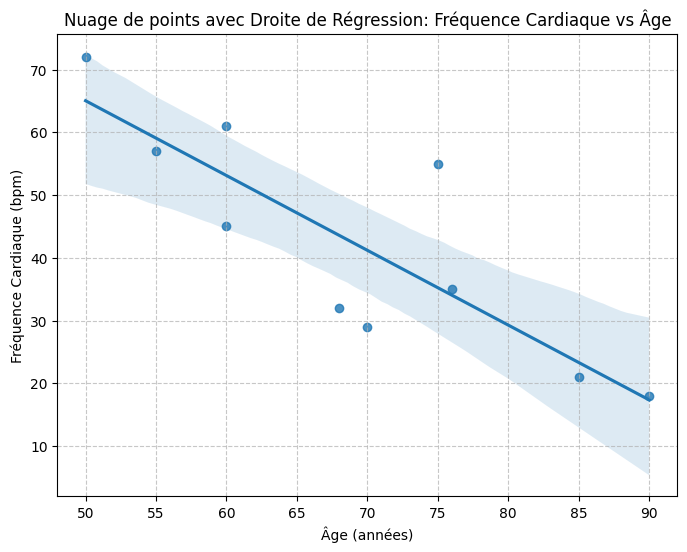

In [ ]:
# Create the scatter plot with a regression line
plt.figure(figsize=(8, 6))
sns.regplot(x='Âge (années)', y='Fréquence Cardiaque (bpm)', data=df_table, scatter_kws={'alpha':0.8})
plt.title('Nuage de points avec Droite de Régression: Fréquence Cardiaque vs Âge')
plt.xlabel('Âge (années)')
plt.ylabel('Fréquence Cardiaque (bpm)')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()